In [1]:
import os
import sys
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..', 'utility')))
os.environ["CUDA_VISIBLE_DEVICES"] = "0,1"  
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1'  # or any {'0', '1', '2'}

from sklearn.preprocessing      import MinMaxScaler
from keras.models               import Model
from keras.layers               import Input, Conv1D, MaxPooling1D, UpSampling1D, Dense, Flatten, Reshape, ZeroPadding1D, Concatenate, Lambda, Multiply, Minimum, Maximum, LSTM, Masking
from keras.layers               import GlobalAveragePooling1D, RepeatVector
from tensorflow.keras.callbacks import EarlyStopping
from keras.constraints          import NonNeg
from preProcessingDataTEP       import PreProcessData
# from matpilotDraw               import MatPlot

import tensorflow           as tf
import numpy                as np
import pandas               as pd
import matplotlib.pyplot    as plt
import random
import warnings
import json
epochTrain          = 200

env                 = 3
seedNumber          = 805

tf.random.set_seed(seedNumber)
np.random.seed(seedNumber)
random.seed(seedNumber)

warnings.filterwarnings('ignore') 

with open('utility/modelConfig.json', 'r') as configFile:
    config = json.load(configFile)
myConfig   = config["tep"]


prePro          = PreProcessData(config=myConfig)
# -----------------------------
# Load and prepare data
# -----------------------------
allWithoutLabel      = ['D feed',                   'E Feed',                   'A Feed',                   'A and C Feed',         'Recycle',              'Purge', 
                        'Separator',                'Stripper',                 'Steam',                    'Reactor Coolant',      'Condenser Coolant',    'Agitator',                 # 12 manipulated variables
                        'msv A Feed',               'msv D Feed',               'msv E Feed',               'msv A and C Feed',     'Recycle Flow',         'Reactor Feed Rate',        # 41 measured variables
                        'Reactor Pressure',         'Reactor Temperature',      'Purge Rate',               'Product Sep Temp', 
                        'Product Sep Pressure',     'Product Sep Underflow',    'Stripper Pressure',        'Reactor Coolant Temp',
                        'Stripper Underflow',       'Stripper Temp',            'Stripper Steam Flow',      'Compressor Work',      
                        'Separator Coolant Temp',   'Component A to Reactor',   'Component B to Reactor',   'Component C to Reactor',
                        'Component D to Reactor',   'Component E to Reactor',   'Component F to Reactor',   'Component A to Purge',
                        'Component B to Purge',     'Component C to Purge',     'Component D to Purge',     'Component E to Purge',
                        'Component F to Purge',     'Component G to Purge',     'Component H to Purge',     'Component D to Product',
                        'Component E to Product',   'Component F to Product',   'Component G to Product',   'Component H to Product',
                        ]     #"rul"

reacLabel           = ['Reactor Coolant', 'Reactor Coolant Temp', 'Reactor Feed Rate', 'Reactor Pressure', 'Reactor Temperature']
sepLabel            = ['Separator', 'Product Sep Temp', 'Product Sep Underflow', 'Separator Coolant Temp', 'E Feed']
stripLabel          = ['Stripper', 'Stripper Underflow', 'E Feed', 'Component B to Reactor', 'Component F to Reactor']

reac_indices        = [allWithoutLabel.index(label) for label in reacLabel]
sep_indices         = [allWithoutLabel.index(label) for label in sepLabel]
strip_indices       = [allWithoutLabel.index(label) for label in stripLabel]
print("Reactor indices: ", reac_indices)
print("Separator indices: ", sep_indices)
print("Stripper indices: ", strip_indices)

outputDir           = os.path.expanduser(prePro.config["dataDir"])

df                  = prePro.loadDataFromH5Format(dir = outputDir, name="data/teps.h5", case="all", reduceSampleRate = True)

# ---------------------------
# Subtract time and adjust
# Remove data before time 40
for idx in df.keys():
    df[idx]         = df[idx][df[idx]["Time"] >= 40]  # Remove data before time 40
    df[idx]["Time"] = df[idx]["Time"] - 40  # Adjust time to start from 0
    df[idx]         = df[idx].reset_index(drop=True)  # Reset index after filtering

withRULData         = prePro.addRULAndEnvironment(df)

# ---------------------------
# For data
cleanData           = prePro.cleanData(   rawSignal         =   withRULData,
                                        columnName          =   allWithoutLabel,
                                        getMovingAverage    =   False,
                                        flipToDown          =   True)
# ---------------------------
# For label, flip only
cleanData           = prePro.cleanData(rawSignal            =   cleanData,
                                        columnName          =   prePro.degraLiq,
                                        getMovingAverage    =   False,
                                        flipToDown          =   True)

print(cleanData[1].head())

# ==============================
# This function is used to prepare 
# the data
# -----------------------------
def dataHandling(df, idName = 'Id', sensorUsed=None, scaler = None,curEnv = None, normalize = True):
    # -----------------------------
    # Init variables
    # sensorUsed        = ['s2','s3','s4','s7','s8','s9','s11','s12','s13','s14','s15','s17','s20','s21'] if sensorUsed is None else sensorUsed
    sensorUsed          = allWithoutLabel if sensorUsed is None else sensorUsed
    windowSize          = 30  # Fixed sequence length
    segmentedData       = []
    engineIds           = []
    beginningCycles     = []
    env                 = []

    # -----------------------------
    # Build sliding windows from each engine
    for engId in df[idName].unique():
        dfEngine        = df[df[idName] == engId]
        engineData      = dfEngine[sensorUsed].values
        for start in range(0, len(engineData) - windowSize + 1):
            window = engineData[start : start + windowSize]
            segmentedData.append(window)
            engineIds.append(engId)
            beginningCycles.append(start + 1)
            env.append(curEnv)

    segmentedData           = np.array(segmentedData)  # (N, 30, 14)
    
    # -----------------------------
    # Normalize data
    N, seqLength, numFeatures   = segmentedData.shape                               # Get the shape of the data after converting to numpy array
    if normalize:
        xFlat                       = segmentedData.reshape(N * seqLength, numFeatures)
        scaler                      = MinMaxScaler() if scaler is None else scaler
        xFlatScaled                 = scaler.fit_transform(xFlat)
        segmentedXScaled            = xFlatScaled.reshape(N, seqLength, numFeatures)
    else:
        segmentedXScaled            = segmentedData
        scaler                      = None
    return segmentedXScaled, engineIds, beginningCycles, env, seqLength, numFeatures, scaler



2025-06-26 09:44:00.132525: E tensorflow/stream_executor/cuda/cuda_blas.cc:2981] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-06-26 09:44:00.727846: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer.so.7'; dlerror: libnvinfer.so.7: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: :/home/ducan/anaconda3/envs/tensorflow2.10.0Crusher/lib/
2025-06-26 09:44:00.727947: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer_plugin.so.7'; dlerror: libnvinfer_plugin.so.7: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: :/home/ducan/anaconda3/envs/tensorflow2.10.0Crusher/lib/
2025-06-26 09:44:00.727956: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Cannot dlopen some TensorRT libraries. If you would like to use Nvidia GPU with Te

Reactor indices:  [9, 25, 17, 18, 19]
Separator indices:  [6, 21, 23, 30, 1]
Stripper indices:  [7, 26, 1, 32, 36]


Process:59084||2025-06-26 09:44:03,333-INFO [preProcessingDataTEP.py:loadDataFromH5Format():384]:Finish loading data from H5 files at case all...
Process:59084||2025-06-26 09:44:03,762-INFO [preProcessingDataTEP.py:addRULAndEnvironment():433]:Adding rul successfully...
Process:59084||2025-06-26 09:44:03,763-INFO [preProcessingDataTEP.py:cleanData():510]:Cleaning data ...
Process:59084||2025-06-26 09:44:03,764-INFO [preProcessingDataTEP.py:cleanData():530]:Flipping data at case 1
Process:59084||2025-06-26 09:44:05,714-INFO [preProcessingDataTEP.py:cleanData():530]:Flipping data at case 2
Process:59084||2025-06-26 09:44:07,721-INFO [preProcessingDataTEP.py:cleanData():530]:Flipping data at case 3
Process:59084||2025-06-26 09:44:09,704-INFO [preProcessingDataTEP.py:cleanData():530]:Flipping data at case 4
Process:59084||2025-06-26 09:44:11,587-INFO [preProcessingDataTEP.py:cleanData():530]:Flipping data at case 5
Process:59084||2025-06-26 09:44:13,326-INFO [preProcessingDataTEP.py:cleanDa

   Id  Time  environmentID      D feed    E Feed     A Feed  A and C Feed  \
0   1   0.0              1   99.966944  9.725330  23.318625     57.683361   
1   1   0.1              1   99.995680  9.762395  23.267178     57.835898   
2   1   0.2              1   99.994413  9.797887  23.853315     57.596908   
3   1   0.3              1  100.054304  9.750245  22.948780     57.984434   
4   1   0.4              1  100.119779  9.694650  22.757426     57.897216   

     Recycle      Purge  Separator  ...  Component H to Purge  \
0  63.890794   9.466375  33.081267  ...              0.372447   
1  63.890794  10.009741  32.952038  ...              0.482741   
2  63.890794   9.822556  32.799209  ...              0.453314   
3  63.890794   8.071345  32.587945  ...              0.479550   
4  63.890794   5.238184  32.409586  ...              0.501860   

   Component D to Product  Component E to Product  Component F to Product  \
0                0.034249                0.162189                0.08

In [2]:
# ------------------------------------
# Data handling before training
# ------------------------------------
dataEnv1    = cleanData[2]
xScaled1, engineIds1, beginningCycles1,env1, seqLength, numFeatures,_     = dataHandling(dataEnv1, curEnv = 1)
xTimeEnv1, _, _, _, _, _,_                                                = dataHandling(dataEnv1, curEnv = 1, sensorUsed=['Time'], normalize=False)  # Get time data
yRul, _, _, _, _, _, rulScaler1                                           = dataHandling(dataEnv1, curEnv = 1, sensorUsed=['rul'])  # Get RUL data
yRul1                                                                     = yRul[:,-1,:]  # Get last value of each sequence

dataEnv2    = cleanData[3]
xScaled2, engineIds2, beginningCycles2,env2, _, _, _                      = dataHandling(dataEnv2, curEnv = 2)
xTimeEnv2, _, _, _, _, _,_                                                = dataHandling(dataEnv2, curEnv = 2, sensorUsed=['Time'], normalize=False)  # Get time data
yRul, _, _, _, _, _,rulScaler2                                                     = dataHandling(dataEnv2, curEnv = 2, sensorUsed=['rul'])  # Get RUL data
yRul2                                                                     = yRul[:,-1,:]  # Get last value of each sequence

dataEnv3    = cleanData[4]
xScaled3, engineIds3, beginningCycles3, env3,_, _,_                        = dataHandling(dataEnv3, curEnv = 3)
xTimeEnv3, _, _, _, _, _,_                                                = dataHandling(dataEnv3, curEnv = 3, sensorUsed=['Time'], normalize=False)  # Get time data
yRul, _, _, _, _, _, rulScaler3                                           = dataHandling(dataEnv3, curEnv = 3, sensorUsed=['rul'])  # Get RUL data
yRul3                                                                     = yRul[:,-1,:]  # Get last value of each sequence


# -------------------------------------
# Get the environment data
reactorEnv1      = xScaled1[:, :, reac_indices]
reactorEnv2      = xScaled2[:, :, reac_indices]
reactorEnv3      = xScaled3[:, :, reac_indices]
separatorEnv1    = xScaled1[:, :, sep_indices]
separatorEnv2    = xScaled2[:, :, sep_indices]
separatorEnv3    = xScaled3[:, :, sep_indices]
stripperEnv1     = xScaled1[:, :, strip_indices]
stripperEnv2     = xScaled2[:, :, strip_indices]
stripperEnv3     = xScaled3[:, :, strip_indices]

if env==1:
    reactorEnv1      = reactorEnv1
    separatorEnv1    = separatorEnv1
    stripperEnv1     = stripperEnv1
    xTimeEnv1        = xTimeEnv1[:,-1,:]
    yRul1            = yRul1
    rulScaler        = rulScaler1
    engineIds1     = engineIds1

elif env==2:
    reactorEnv1      = reactorEnv2
    separatorEnv1    = separatorEnv2
    stripperEnv1     = stripperEnv2
    xTimeEnv1        = xTimeEnv2[:,-1,:]
    yRul1            = yRul2
    rulScaler        = rulScaler2
    engineIds1     = engineIds2
elif env==3:
    reactorEnv1      = reactorEnv3
    separatorEnv1    = separatorEnv3
    stripperEnv1     = stripperEnv3
    xTimeEnv1        = xTimeEnv3[:,-1,:]
    yRul1            = yRul3
    rulScaler        = rulScaler3
    engineIds1     = engineIds3



# allXScaled          = np.concatenate([xScaled1, xScaled2, xScaled3], axis=0)
# allYRul             = np.concatenate([yRul1, yRul2, yRul3], axis=0)
# allEngineIds        = engineIds1 + engineIds2 + engineIds3
# allBeginningCycles  = beginningCycles1 + beginningCycles2 + beginningCycles3
# # allEnv              = np.array(env1 + env2 + env3 ).reshape(-1, 1)
# allEnv              = np.array(env1 + env2 + env3 )

# ------------------------------------
print(xScaled1.shape, xScaled2.shape, xScaled3.shape)
# print(allXScaled.shape)

print(yRul1.shape, yRul2.shape, yRul3.shape)
# print(allYRul.shape)

print(len(engineIds1), len(engineIds1), len(engineIds1))
# print(len(allEngineIds))

print(len(beginningCycles1), len(beginningCycles2), len(beginningCycles3))
# print(len(allBeginningCycles))

print(len(env1), len(env2), len(env3))
# print(allEnv.shape)


print("Reactor Env 1 shape: ", reactorEnv1.shape)
print("Reactor Env 2 shape: ", reactorEnv2.shape)
print("Reactor Env 3 shape: ", reactorEnv3.shape)
print("Separator Env 1 shape: ", separatorEnv1.shape)
print("Separator Env 2 shape: ", separatorEnv2.shape)
print("Separator Env 3 shape: ", separatorEnv3.shape)
print("Stripper Env 1 shape: ", stripperEnv1.shape)
print("Stripper Env 2 shape: ", stripperEnv2.shape)
print("Stripper Env 3 shape: ", stripperEnv3.shape)


(98059, 30, 50) (99674, 30, 50) (79908, 30, 50)
(79908, 1) (99674, 1) (79908, 1)
79908 79908 79908
98059 99674 79908
98059 99674 79908
Reactor Env 1 shape:  (79908, 30, 5)
Reactor Env 2 shape:  (99674, 30, 5)
Reactor Env 3 shape:  (79908, 30, 5)
Separator Env 1 shape:  (79908, 30, 5)
Separator Env 2 shape:  (99674, 30, 5)
Separator Env 3 shape:  (79908, 30, 5)
Stripper Env 1 shape:  (79908, 30, 5)
Stripper Env 2 shape:  (99674, 30, 5)
Stripper Env 3 shape:  (79908, 30, 5)


### Reactor Env 1

In [3]:
print("Reactor Env 1 shape: ", reactorEnv1.shape)
print("Time Env 1 shape: ", xTimeEnv1.shape)
print("RUL 1 shape: ", yRul1.shape)

Reactor Env 1 shape:  (79908, 30, 5)
Time Env 1 shape:  (79908, 1)
RUL 1 shape:  (79908, 1)


The shape of last layer encoder is (None, 8, 16)
['conv1d_3']
['recon_loss', 'latent_loss']
['conv1d_3']
['recon_loss', 'latent_loss']
Epoch 1/200


2025-06-26 09:44:26.471326: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2025-06-26 09:44:26.472530: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.


562/562 [==============================] - 6s 5ms/step - loss: -0.6436 - recon_loss: 0.1196 - latent_loss: -0.7631 - val_loss: -0.3365 - val_recon_loss: 0.0922 - val_latent_loss: -0.4287
Epoch 2/200
562/562 [==============================] - 3s 5ms/step - loss: -0.7551 - recon_loss: 0.0905 - latent_loss: -0.8456 - val_loss: -0.3940 - val_recon_loss: 0.0913 - val_latent_loss: -0.4853
Epoch 3/200
562/562 [==============================] - 3s 5ms/step - loss: -0.7914 - recon_loss: 0.0907 - latent_loss: -0.8821 - val_loss: -0.4141 - val_recon_loss: 0.0896 - val_latent_loss: -0.5037
Epoch 4/200
562/562 [==============================] - 3s 5ms/step - loss: -0.8131 - recon_loss: 0.0899 - latent_loss: -0.9031 - val_loss: -0.4857 - val_recon_loss: 0.0889 - val_latent_loss: -0.5746
Epoch 5/200
562/562 [==============================] - 3s 5ms/step - loss: -0.8252 - recon_loss: 0.0892 - latent_loss: -0.9144 - val_loss: -0.4780 - val_recon_loss: 0.0889 - val_latent_loss: -0.5669
Epoch 6/200
562/5

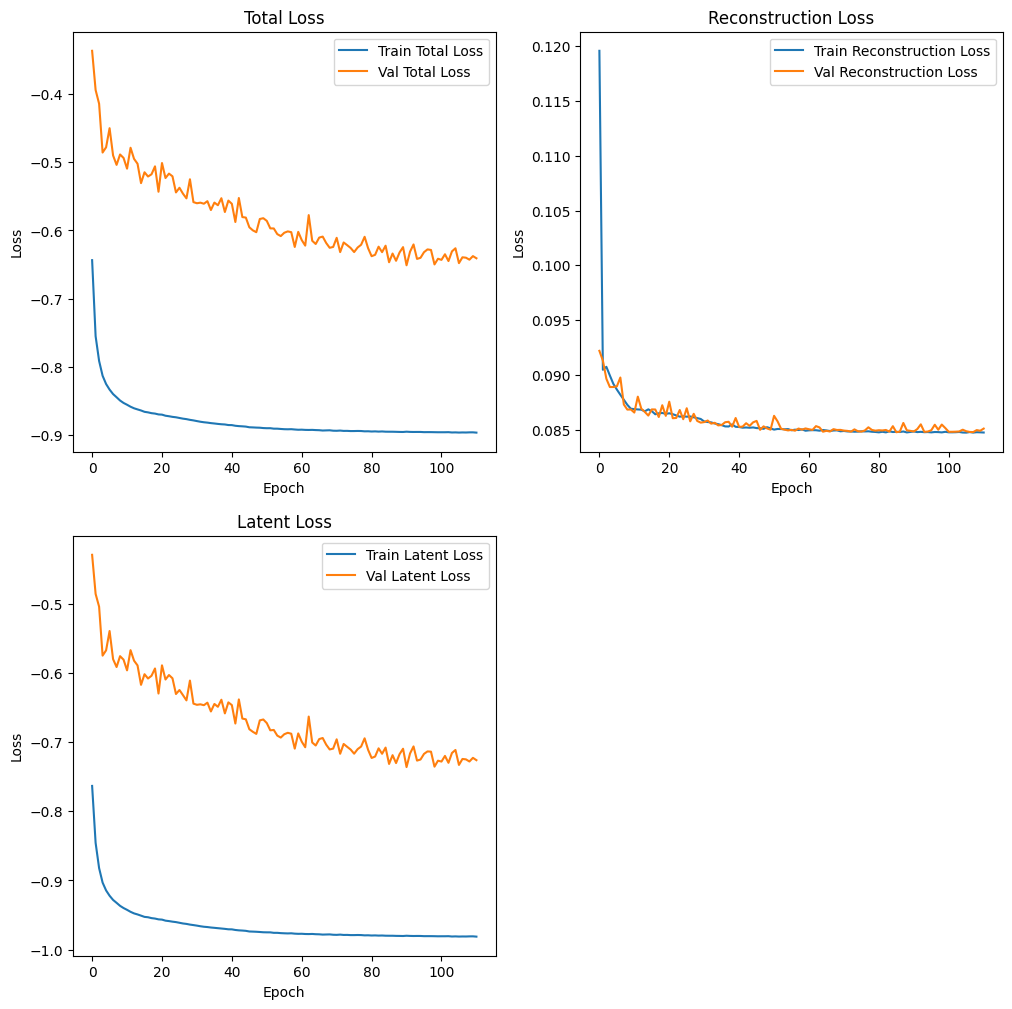

In [4]:
trainNumFeatures = 5
def latentLoss(inputData, type='trendability'):
    x, t = inputData  # x = latent, t = time
    x_mu = tf.reduce_mean(x, axis=0)
    t_mu = tf.reduce_mean(t, axis=0)
    
    cov = tf.reduce_sum((x - x_mu) * (t - t_mu))
    std = tf.math.sqrt(tf.reduce_sum(tf.square(x - x_mu))) * tf.math.sqrt(tf.reduce_sum(tf.square(t - t_mu)))
    
    loss = cov / (std + 1e-8)  # add epsilon to avoid divide by zero
    return loss  # We minimize, so make it negative

# ==============================
# Encoder block
# ------------------------------
inputs                      = Input(shape=(seqLength, trainNumFeatures))
inputTime                   = Input(shape=(1), name="input_time")  # Time input for latent loss

x                           = Conv1D(32, 3, activation='relu', padding='same')(inputs)
x                           = MaxPooling1D(2, padding='same')(x)
x                           = Conv1D(16, 3, activation='relu', padding='same')(x)
lastAELayer                 = MaxPooling1D(2, padding='same',name='lastAELayer')(x)
x                           = GlobalAveragePooling1D()(lastAELayer)
latent                      = Dense(1, name='latent')(x)  # HI directly here

print("The shape of last layer encoder is", lastAELayer.shape)

# ==============================
# Decoder block
# -----------------------------
x           = Dense((seqLength // 4) * 16, activation='relu')(latent)  # (7 * 16)
x           = Reshape((seqLength // 4, 16))(x)  # Shape: (7, 16)
x           = UpSampling1D(2)(x)  # Shape: (14, 16)
x           = Conv1D(32, 3, activation='relu', padding='same')(x)  # Shape: (14, 32)
x           = UpSampling1D(2)(x)  # Shape: (28, 32)
x           = ZeroPadding1D(padding=(1, 1))(x)  # Pad to get (30, 32)
decoded     = Conv1D(trainNumFeatures, 3, activation='linear', padding='same')(x)  # Shape: (30, 14)


cnnAEModel      = Model([inputs, inputTime], outputs=decoded)

# ==============================
# Add the loss function
# -----------------------------
recon_loss      = tf.reduce_mean(tf.abs(decoded - inputs))
cnnAEModel.add_loss(recon_loss)
cnnAEModel.add_metric(recon_loss, name="recon_loss", aggregation="mean")


latent_loss_value = latentLoss((latent, inputTime))
cnnAEModel.add_loss(latent_loss_value)
cnnAEModel.add_metric(latent_loss_value, name="latent_loss", aggregation="mean")

cnnAEModel.compile( optimizer    = 'adam')  # adjust weights as needed


# ==============================
# Train the model
# ------------------------------

print(cnnAEModel.output_names)  # ['reconstruction']
print(cnnAEModel.metrics_names) # ['loss', 'mae', 'ssProbability']


early_stop = EarlyStopping(
    monitor='val_loss',
    patience=20,          # number of epochs with no improvement after which training stops
    restore_best_weights=True,
    verbose=1
)

# ==============================
# Train the model
# ------------------------------
print(cnnAEModel.output_names)   # ['reconstruction']
print(cnnAEModel.metrics_names)  # ['loss', 'recon_loss', 'latent_loss']

history = cnnAEModel.fit(
    [reactorEnv1, xTimeEnv1],
    reactorEnv1,
    epochs=epochTrain,
    batch_size=128,
    validation_split=0.1,
    callbacks=[early_stop],       # <<< Add this line
    verbose=1
)
# history = cnnAEModel.fit([reactorEnv1, xTimeEnv1], reactorEnv1, epochs=epochTrain, batch_size=128, validation_split=0.1, verbose=1)


print(history.history.keys())


plt.figure(figsize=(12, 12))

plt.subplot(2, 2, 1)
plt.plot(history.history['loss'], label='Train Total Loss')
plt.plot(history.history['val_loss'], label='Val Total Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Total Loss')
plt.legend()

# --- Plot reconstruction loss ---
plt.subplot(2, 2, 2)
plt.plot(history.history['recon_loss'], label='Train Reconstruction Loss')
plt.plot(history.history['val_recon_loss'], label='Val Reconstruction Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Reconstruction Loss')
plt.legend()

# --- Plot latent loss ---
plt.subplot(2, 2, 3)
plt.plot(history.history['latent_loss'], label='Train Latent Loss')
plt.plot(history.history['val_latent_loss'], label='Val Latent Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Latent Loss')
plt.legend()


2498/2498 [==============================] - 3s 1ms/step
[[ 2.9 ]
 [ 3.  ]
 [ 3.1 ]
 ...
 [85.25]
 [85.35]
 [85.45]]


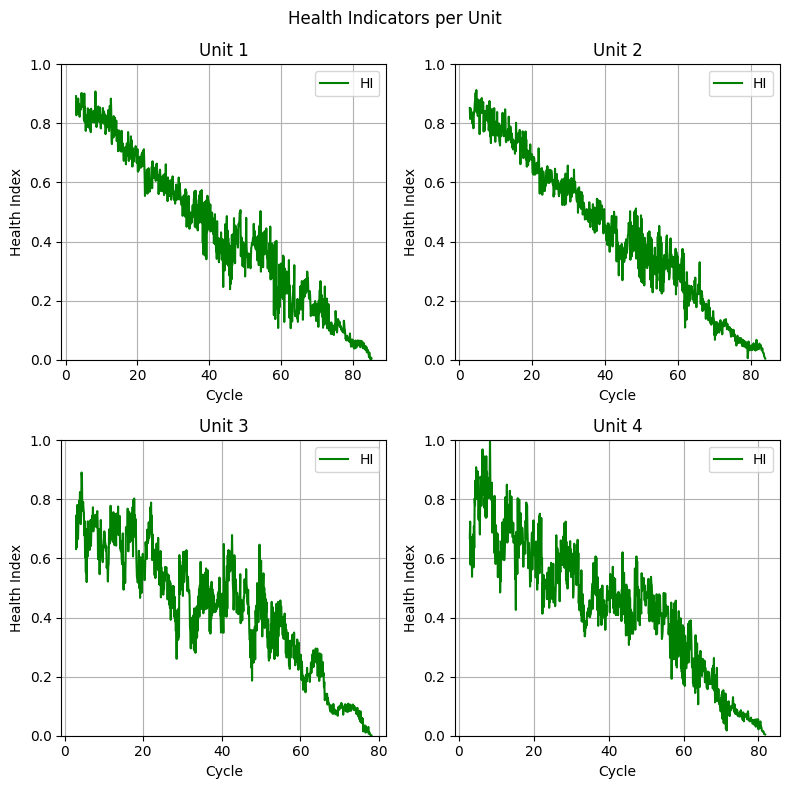

In [5]:
from utility.matpilotDraw   import MatPlot
# ==============================
# Extract latent HI values
# ------------------------------
encoderReac = Model(    inputs  =  cnnAEModel.input,
                    outputs = [cnnAEModel.get_layer('lastAELayer').output, cnnAEModel.get_layer('latent').output],  name="encoderSubModelReac")  # Extract the encoder part of the model
                                                    
_, rawHIValues      = encoderReac.predict([reactorEnv1, xTimeEnv1], verbose=1)  # Get the latent values (HI) from the encoder
reacHIValues            = rawHIValues.flatten()                        # Flatten to 1D array
# hiValues            = (hiValues - hiValues.min()) / (hiValues.max() - hiValues.min())           # Normalize HI


# print(beginningCycles1)
# print(xTimeEnv1[0].shape)
print(xTimeEnv1)

dfHI                = pd.DataFrame({'env'   : np.full_like(reacHIValues, fill_value=1),
                                    'id'    : np.array(engineIds1),
                                    'cycle' : xTimeEnv1.squeeze(),  # Use the last time value as cycle
                                    'HI'    : reacHIValues})              # Build dataframe for plotting


hiThresholdReac     = max(dfHI.groupby('id')['HI'].min())
upperHIReac         = max(dfHI.groupby('id')['HI'].max())
dfHI                = dfHI[dfHI['HI'] > hiThresholdReac]                                          # Filter out engines with HI > threshold

dfHI["HI"]          = (dfHI["HI"] - hiThresholdReac) / (upperHIReac - hiThresholdReac)           # Normalize HI


plot1 = MatPlot()
plot1.plot_HI_by_id(
    dfHI,
    hi_columns=["HI"],
    num_rows=2,
    num_cols=2,
    colors=['green'],
    title="Health Indicators per Unit",
    y_lim=[0, 1]  # adjust if needed
)


### Sep Env 1

The shape of last layer encoder is (None, 8, 16)
['conv1d_7']
['recon_loss', 'latent_loss']
Epoch 1/200
562/562 [==============================] - 4s 5ms/step - loss: -0.7808 - recon_loss: 0.1106 - latent_loss: -0.8914 - val_loss: -0.5199 - val_recon_loss: 0.0545 - val_latent_loss: -0.5744
Epoch 2/200
562/562 [==============================] - 2s 4ms/step - loss: -0.8820 - recon_loss: 0.0468 - latent_loss: -0.9288 - val_loss: -0.5416 - val_recon_loss: 0.0444 - val_latent_loss: -0.5860
Epoch 3/200
562/562 [==============================] - 3s 4ms/step - loss: -0.8906 - recon_loss: 0.0427 - latent_loss: -0.9333 - val_loss: -0.5501 - val_recon_loss: 0.0422 - val_latent_loss: -0.5923
Epoch 4/200
562/562 [==============================] - 3s 6ms/step - loss: -0.8942 - recon_loss: 0.0426 - latent_loss: -0.9368 - val_loss: -0.5579 - val_recon_loss: 0.0418 - val_latent_loss: -0.5997
Epoch 5/200
562/562 [==============================] - 3s 6ms/step - loss: -0.8979 - recon_loss: 0.0433 - latent

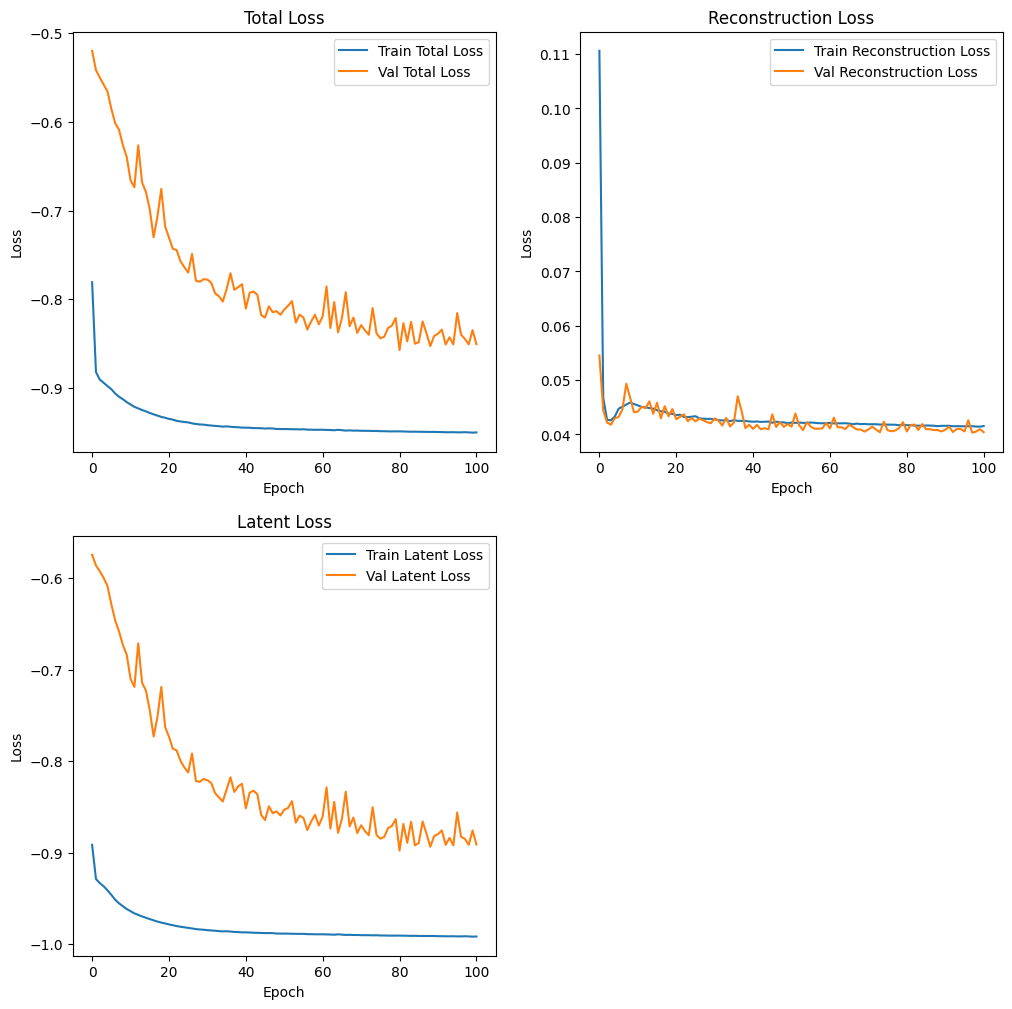

In [6]:

# ==============================
# Encoder block
# ------------------------------
inputs                      = Input(shape=(seqLength, trainNumFeatures))
inputTime                   = Input(shape=(1), name="input_time")  # Time input for latent loss

x                           = Conv1D(32, 3, activation='relu', padding='same')(inputs)
x                           = MaxPooling1D(2, padding='same')(x)
x                           = Conv1D(16, 3, activation='relu', padding='same')(x)
lastAELayer                 = MaxPooling1D(2, padding='same',name='lastAELayer')(x)
x                           = GlobalAveragePooling1D()(lastAELayer)
latent                      = Dense(1, name='latent')(x)  # HI directly here

print("The shape of last layer encoder is", lastAELayer.shape)

# ==============================
# Decoder block
# -----------------------------
x           = Dense((seqLength // 4) * 16, activation='relu')(latent)  # (7 * 16)
x           = Reshape((seqLength // 4, 16))(x)  # Shape: (7, 16)
x           = UpSampling1D(2)(x)  # Shape: (14, 16)
x           = Conv1D(32, 3, activation='relu', padding='same')(x)  # Shape: (14, 32)
x           = UpSampling1D(2)(x)  # Shape: (28, 32)
x           = ZeroPadding1D(padding=(1, 1))(x)  # Pad to get (30, 32)
decoded     = Conv1D(trainNumFeatures, 3, activation='linear', padding='same')(x)  # Shape: (30, 14)


cnnAEModel      = Model([inputs, inputTime], outputs=decoded)

# ==============================
# Add the loss function
# -----------------------------
recon_loss      = tf.reduce_mean(tf.abs(decoded - inputs))
cnnAEModel.add_loss(recon_loss)
cnnAEModel.add_metric(recon_loss, name="recon_loss", aggregation="mean")


latent_loss_value = latentLoss((latent, inputTime))
cnnAEModel.add_loss(latent_loss_value)
cnnAEModel.add_metric(latent_loss_value, name="latent_loss", aggregation="mean")

cnnAEModel.compile( optimizer    = 'adam')  # adjust weights as needed


# ==============================
# Train the model
# ------------------------------

print(cnnAEModel.output_names)  # ['reconstruction']
print(cnnAEModel.metrics_names) # ['loss', 'mae', 'ssProbability']


early_stop = EarlyStopping(
    monitor='val_loss',
    patience=20,          # number of epochs with no improvement after which training stops
    restore_best_weights=True,
    verbose=1
)


history = cnnAEModel.fit([separatorEnv1, xTimeEnv1], separatorEnv1, epochs=epochTrain, batch_size=128, validation_split=0.1, callbacks=[early_stop],verbose=1)


print(history.history.keys())


plt.figure(figsize=(12, 12))

plt.subplot(2, 2, 1)
plt.plot(history.history['loss'], label='Train Total Loss')
plt.plot(history.history['val_loss'], label='Val Total Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Total Loss')
plt.legend()

# --- Plot reconstruction loss ---
plt.subplot(2, 2, 2)
plt.plot(history.history['recon_loss'], label='Train Reconstruction Loss')
plt.plot(history.history['val_recon_loss'], label='Val Reconstruction Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Reconstruction Loss')
plt.legend()

# --- Plot latent loss ---
plt.subplot(2, 2, 3)
plt.plot(history.history['latent_loss'], label='Train Latent Loss')
plt.plot(history.history['val_latent_loss'], label='Val Latent Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Latent Loss')
plt.legend()


2498/2498 [==============================] - 3s 1ms/step


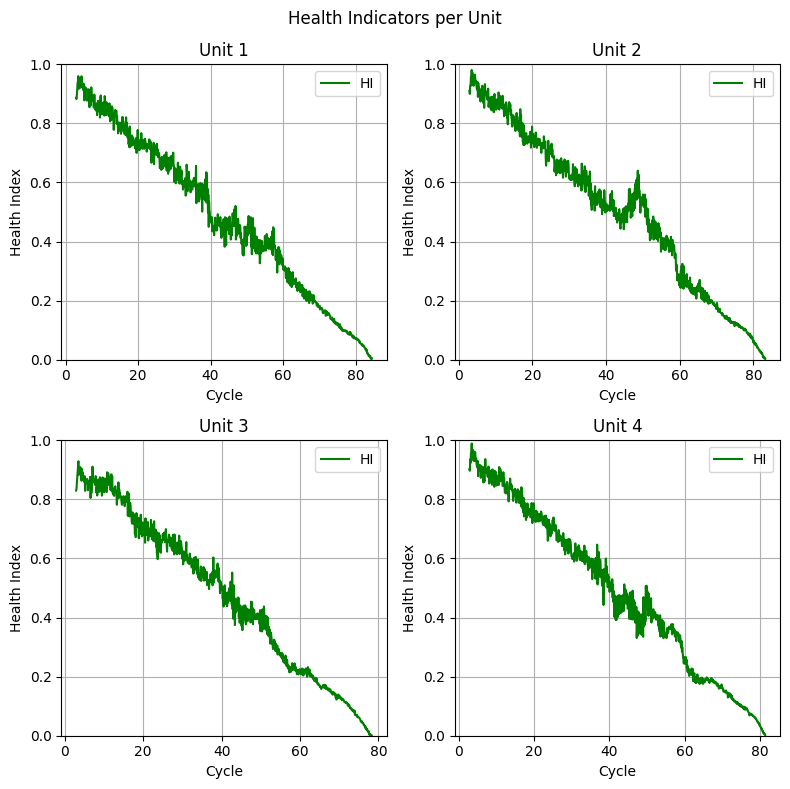

In [7]:
from utility.matpilotDraw   import MatPlot
# ==============================
# Extract latent HI values
# ------------------------------
encoderSep = Model(    inputs  =  cnnAEModel.input,
                    outputs = [cnnAEModel.get_layer('lastAELayer').output, cnnAEModel.get_layer('latent').output],  name="encoderSubmodelSep")

_, rawHIValues      = encoderSep.predict([separatorEnv1, xTimeEnv1], verbose=1)  # Get the latent values (HI) from the encoder
sepHIValues            = rawHIValues.flatten()                        # Flatten to 1D array
# hiValues            = (hiValues - hiValues.min()) / (hiValues.max() - hiValues.min())           # Normalize HI

# print(hiValues.shape)
# print(reactorEnv1.shape)
# print(engineIds1.shape)
# print(beginningCycles1.shape)


dfHI                = pd.DataFrame({'env'   : np.full_like(sepHIValues, fill_value=1),
                                    'id'    : np.array(engineIds1),
                                    'cycle' : np.array(xTimeEnv1.squeeze()),  # Use the last time value as cycle
                                    'HI'    : sepHIValues})              # Build dataframe for plotting


hiThresholdSep         = max(dfHI.groupby('id')['HI'].min())
upperHISep             = max(dfHI.groupby('id')['HI'].max())
dfHI                = dfHI[dfHI['HI'] > hiThresholdSep]                                          # Filter out engines with HI > threshold

dfHI["HI"]          = (dfHI["HI"] - hiThresholdSep) / (upperHISep - hiThresholdSep)           # Normalize HI


plot1 = MatPlot()
plot1.plot_HI_by_id(
    dfHI,
    hi_columns=["HI"],
    num_rows=2,
    num_cols=2,
    colors=['green'],
    title="Health Indicators per Unit",
    y_lim=[0, 1]  # adjust if needed
)


### Stripper Env1

The shape of last layer encoder is (None, 8, 16)
['conv1d_11']
['recon_loss', 'latent_loss']
['conv1d_11']
['recon_loss', 'latent_loss']
Epoch 1/200
562/562 [==============================] - 4s 5ms/step - loss: -0.8375 - recon_loss: 0.1183 - latent_loss: -0.9558 - val_loss: -0.7940 - val_recon_loss: 0.0581 - val_latent_loss: -0.8521
Epoch 2/200
562/562 [==============================] - 3s 5ms/step - loss: -0.9388 - recon_loss: 0.0518 - latent_loss: -0.9906 - val_loss: -0.8380 - val_recon_loss: 0.0486 - val_latent_loss: -0.8866
Epoch 3/200
562/562 [==============================] - 3s 5ms/step - loss: -0.9456 - recon_loss: 0.0483 - latent_loss: -0.9938 - val_loss: -0.8643 - val_recon_loss: 0.0464 - val_latent_loss: -0.9107
Epoch 4/200
562/562 [==============================] - 3s 6ms/step - loss: -0.9483 - recon_loss: 0.0468 - latent_loss: -0.9951 - val_loss: -0.8732 - val_recon_loss: 0.0475 - val_latent_loss: -0.9207
Epoch 5/200
562/562 [==============================] - 5s 9ms/step 

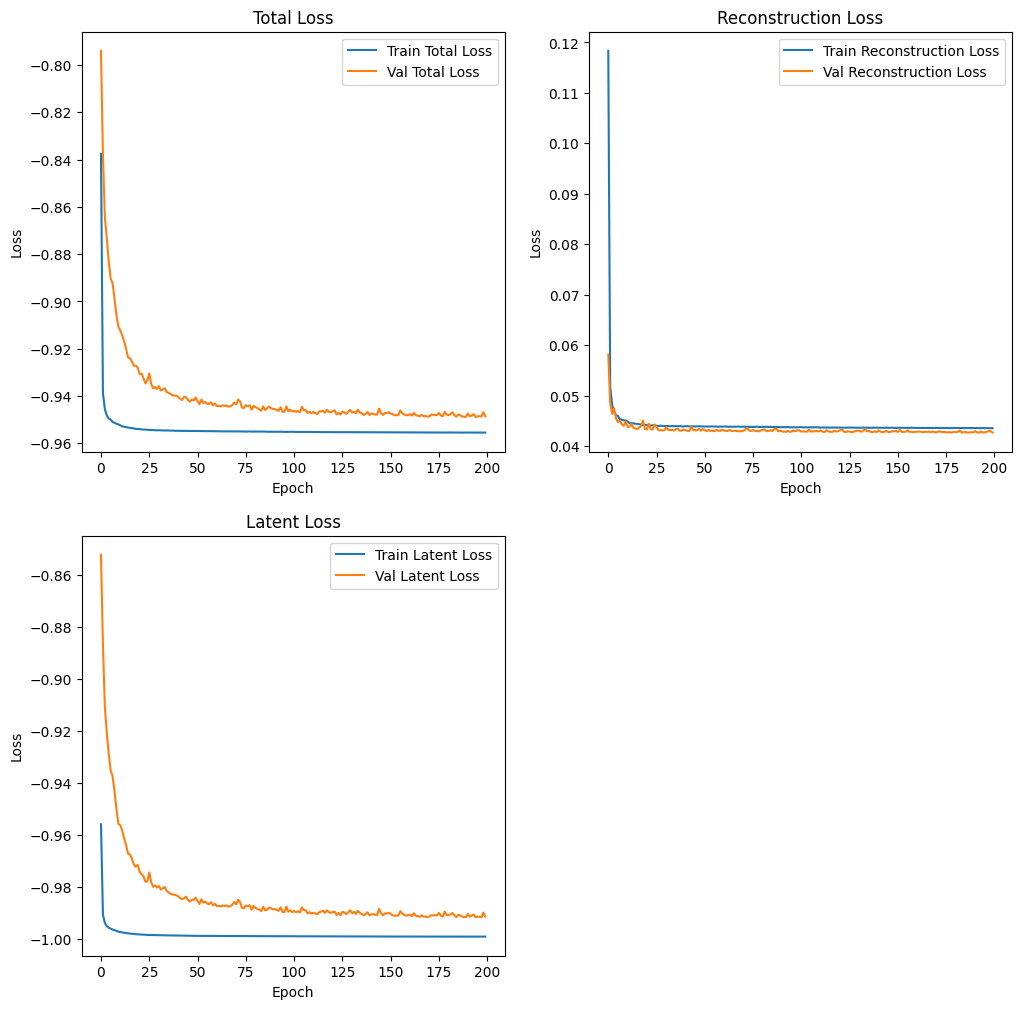

In [8]:

# ==============================
# Encoder block
# ------------------------------
inputs                      = Input(shape=(seqLength, trainNumFeatures))
inputTime                   = Input(shape=(1), name="input_time")  # Time input for latent loss

x                           = Conv1D(32, 3, activation='relu', padding='same')(inputs)
x                           = MaxPooling1D(2, padding='same')(x)
x                           = Conv1D(16, 3, activation='relu', padding='same')(x)
lastAELayer                 = MaxPooling1D(2, padding='same',name='lastAELayer')(x)
x                           = GlobalAveragePooling1D()(lastAELayer)
latent                      = Dense(1, name='latent')(x)  # HI directly here

print("The shape of last layer encoder is", lastAELayer.shape)

# ==============================
# Decoder block
# -----------------------------
x           = Dense((seqLength // 4) * 16, activation='relu')(latent)  # (7 * 16)
x           = Reshape((seqLength // 4, 16))(x)  # Shape: (7, 16)
x           = UpSampling1D(2)(x)  # Shape: (14, 16)
x           = Conv1D(32, 3, activation='relu', padding='same')(x)  # Shape: (14, 32)
x           = UpSampling1D(2)(x)  # Shape: (28, 32)
x           = ZeroPadding1D(padding=(1, 1))(x)  # Pad to get (30, 32)
decoded     = Conv1D(trainNumFeatures, 3, activation='linear', padding='same')(x)  # Shape: (30, 14)


cnnAEModel      = Model([inputs, inputTime], outputs=decoded)

# ==============================
# Add the loss function
# -----------------------------
recon_loss      = tf.reduce_mean(tf.abs(decoded - inputs))
cnnAEModel.add_loss(recon_loss)
cnnAEModel.add_metric(recon_loss, name="recon_loss", aggregation="mean")


latent_loss_value = latentLoss((latent, inputTime))
cnnAEModel.add_loss(latent_loss_value)
cnnAEModel.add_metric(latent_loss_value, name="latent_loss", aggregation="mean")

cnnAEModel.compile( optimizer    = 'adam')  # adjust weights as needed


# ==============================
# Train the model
# ------------------------------

print(cnnAEModel.output_names)  # ['reconstruction']
print(cnnAEModel.metrics_names) # ['loss', 'mae', 'ssProbability']



early_stop = EarlyStopping(
    monitor='val_loss',
    patience=20,          # number of epochs with no improvement after which training stops
    restore_best_weights=True,
    verbose=1
)

# ==============================
# Train the model
# ------------------------------
print(cnnAEModel.output_names)   # ['reconstruction']
print(cnnAEModel.metrics_names)  # ['loss', 'recon_loss', 'latent_loss']

history = cnnAEModel.fit([stripperEnv1, xTimeEnv1], stripperEnv1, epochs=epochTrain, batch_size=128, validation_split=0.1, callbacks=[early_stop], verbose=1)


print(history.history.keys())


plt.figure(figsize=(12, 12))

plt.subplot(2, 2, 1)
plt.plot(history.history['loss'], label='Train Total Loss')
plt.plot(history.history['val_loss'], label='Val Total Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Total Loss')
plt.legend()

# --- Plot reconstruction loss ---
plt.subplot(2, 2, 2)
plt.plot(history.history['recon_loss'], label='Train Reconstruction Loss')
plt.plot(history.history['val_recon_loss'], label='Val Reconstruction Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Reconstruction Loss')
plt.legend()

# --- Plot latent loss ---
plt.subplot(2, 2, 3)
plt.plot(history.history['latent_loss'], label='Train Latent Loss')
plt.plot(history.history['val_latent_loss'], label='Val Latent Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Latent Loss')
plt.legend()


2498/2498 [==============================] - 3s 1ms/step


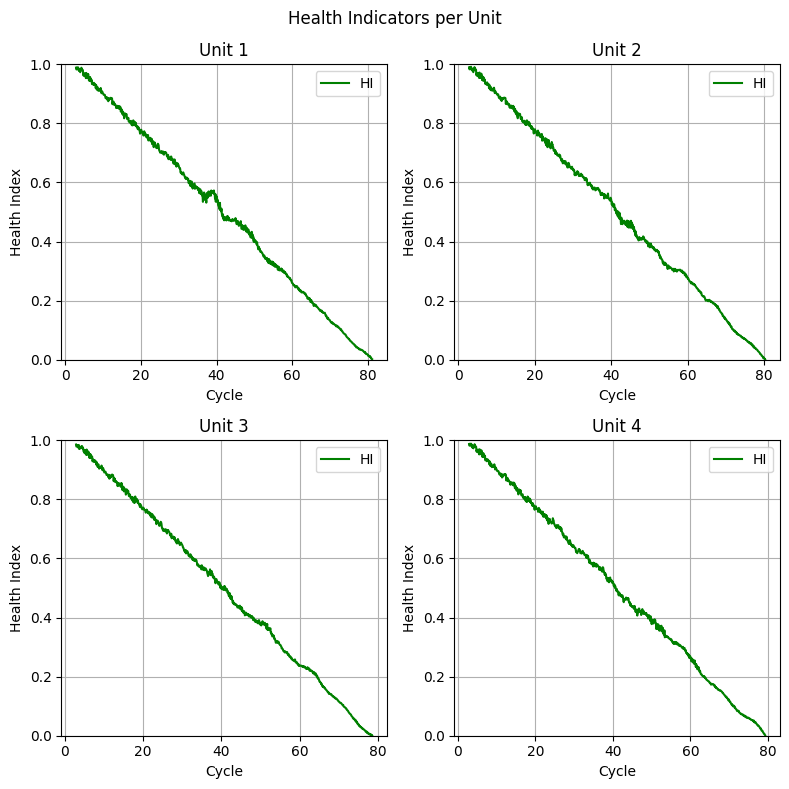

In [9]:
from utility.matpilotDraw   import MatPlot
# ==============================
# Extract latent HI values
# ------------------------------
encoderStrip = Model(    inputs  =  cnnAEModel.input,
                    outputs = [cnnAEModel.get_layer('lastAELayer').output, cnnAEModel.get_layer('latent').output],  name="encoderSubmodelStrip")

_, rawHIValues      = encoderStrip.predict([stripperEnv1, xTimeEnv1], verbose=1)  # Get the latent values (HI) from the encoder
stripHIValues            = rawHIValues.flatten()                        # Flatten to 1D array
# hiValues            = (hiValues - hiValues.min()) / (hiValues.max() - hiValues.min())           # Normalize HI

# print(hiValues.shape)
# print(reactorEnv1.shape)
# print(engineIds1.shape)
# print(beginningCycles1.shape)


dfHI                = pd.DataFrame({'env'   : np.full_like(stripHIValues, fill_value=1),
                                    'id'    : np.array(engineIds1),
                                    'cycle' : np.array(xTimeEnv1.squeeze()),  # Use the last time value as cycle
                                    'HI'    : stripHIValues})              # Build dataframe for plotting


hiThresholdStrip         = max(dfHI.groupby('id')['HI'].min())
upperHIStrip             = max(dfHI.groupby('id')['HI'].max())
dfHI                    = dfHI[dfHI['HI'] > hiThresholdStrip]                              # Filter out engines with HI > threshold

dfHI["HI"]              = (dfHI["HI"] - hiThresholdStrip) / (upperHIStrip - hiThresholdStrip)           # Normalize HI


plot1 = MatPlot()
plot1.plot_HI_by_id(
    dfHI,
    hi_columns=["HI"],
    num_rows=2,
    num_cols=2,
    colors=['green'],
    title="Health Indicators per Unit",
    y_lim=[0, 1]  # adjust if needed
)


79908
(79908, 1)
(79908,) (79908,) (79908,)
        id  cycle    reacHI     sepHI   stripHI     sysHI
0        1   2.90  0.990959  0.978725  0.990959  0.978725
1        1   3.00  0.988388  0.978415  0.989333  0.978415
2        1   3.10  0.987751  0.978578  0.988853  0.978578
3        1   3.20  0.987497  0.979055  0.988754  0.979055
4        1   3.30  0.987197  0.979808  0.988831  0.979808
...    ...    ...       ...       ...       ...       ...
79835  100  78.25  0.859833  0.756991  0.005986  0.005986
79836  100  78.35  0.859629  0.756634  0.004677  0.004677
79837  100  78.45  0.859444  0.756270  0.003375  0.003375
79838  100  78.55  0.859258  0.755912  0.002073  0.002073
79839  100  78.65  0.859075  0.755539  0.000757  0.000757

[75720 rows x 6 columns]


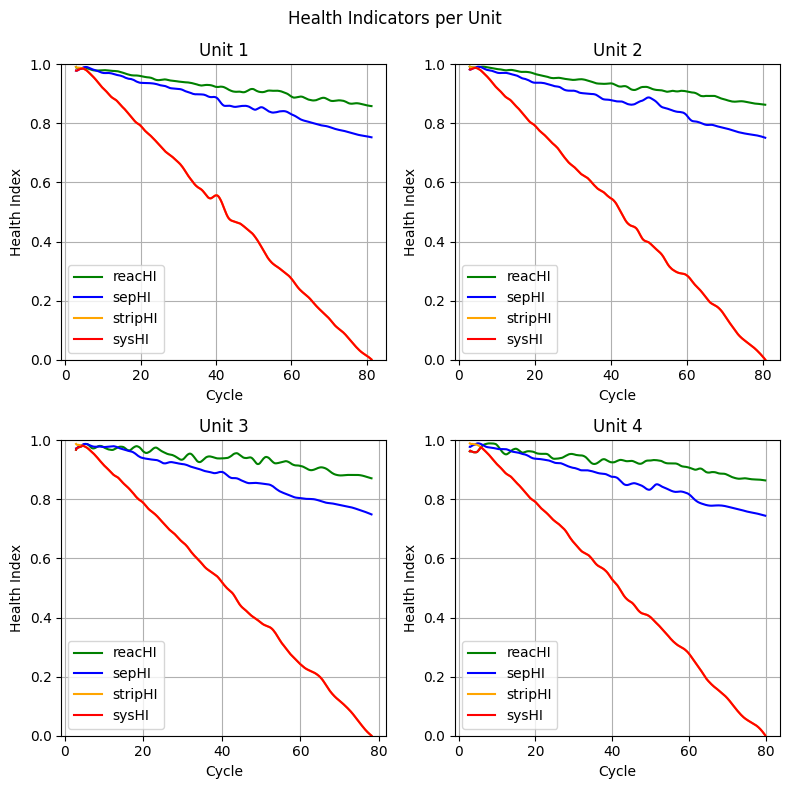

In [10]:
# print(dfHIAll)
# ==============================
# Move all HI to the same peak
hiColumns        = ['reacHI', 'sepHI', 'stripHI']

print(len(engineIds1))
print(xTimeEnv1.shape)
print(reacHIValues.shape, sepHIValues.shape, stripHIValues.shape)

dfHIAll          = pd.DataFrame({
                                    'id'            : np.array(engineIds1),
                                    'cycle'         : xTimeEnv1.squeeze(),
                                    # 'systemHI'      : sysHi.flatten(),
                                    'reacHI'        : reacHIValues.copy(),
                                    'sepHI'         : sepHIValues.copy(),
                                    'stripHI'       : stripHIValues.copy(),
                                    })              # Build dataframe for plotting



for _ in range(2):
    for col in hiColumns:
        dfHIAll[col] = (dfHIAll.groupby('id')[col].transform(lambda x: x.rolling(window=15, min_periods=1).mean()))


hiColumns          = ['reacHI', 'sepHI', 'stripHI']
globalMax           = dfHIAll.groupby('id')[hiColumns].max().max(axis = 1).reset_index(name='globalMax')   # Get the global maximum for each ids
maxPerIdEachCol     = dfHIAll.groupby('id')[hiColumns].max().reset_index()                                 # Get the maximum value for each column across all ids

shiftMatrix = pd.DataFrame({    'reacHI': globalMax['globalMax'] -  maxPerIdEachCol['reacHI'],
                                'sepHI':  globalMax['globalMax'] -  maxPerIdEachCol['sepHI'],
                                'stripHI': globalMax['globalMax'] - maxPerIdEachCol['stripHI'],
                            })                                                                             # Create a shift matrix to adjust the HI values

dfHIAll[hiColumns] =  dfHIAll.groupby('id')[hiColumns].apply(lambda group: group + shiftMatrix.loc[group.name-1,:])  # Adjust the HI values by adding the shift matrix


upperHIs            = max(globalMax['globalMax'])                                                           # Use the global maximum for normalization
hiThreshold         = max(dfHIAll.groupby('id')['stripHI'].min())


dfHIAll             = dfHIAll[dfHIAll['stripHI'] > hiThreshold]                                             # Filter out engines with HI > threshold

dfHIAll[hiColumns]  = (dfHIAll[hiColumns] - hiThreshold) / (upperHIs - hiThreshold)           # Normalize HI


dfHIAll["sysHI"]    = dfHIAll[hiColumns].min(axis=1)  # Calculate the system HI as the mean of the individual HIs
print(dfHIAll)


plot = MatPlot()
plot.plot_HI_by_id(
    dfHIAll,
    hi_columns=["reacHI", "sepHI", "stripHI", "sysHI"],
    num_rows=2,
    num_cols=2,
    colors=['green', 'blue', 'orange', 'red'],
    title="Health Indicators per Unit",
    y_lim=[0, 1]  # adjust if needed
)

#### System

In [11]:
# ============================
# Freeze the encoder
# ----------------------------
print("==========================")
print("           Encoder          ")
print("==========================")
encoderReac.summary()
for layer in encoderReac.layers:
    layer.trainable = False
for layer in encoderSep.layers:
    layer.trainable = False
for layer in encoderStrip.layers:
    layer.trainable = False

# ============================
# The loss function for HI selection
# ----------------------------
def selection_entropy_loss(y_true, y_pred):
    """
    y_pred: hiMatrixOutput -> shape (None, 3)
    We ignore y_true because we don't have a label for it.
    This returns the negative sum(p * log p).
    """
    # Add a small constant (1e-10) inside the log to avoid log(0).
    # The shape of this expression is (batch_size,).
    neg_entropy = -tf.reduce_sum(y_pred * tf.math.log(y_pred + 1e-10), axis=-1)
    return neg_entropy




# ===============================
# MODEL
# ===============================
input1_seq  = Input(shape=(seqLength, trainNumFeatures), name="input1_seq")
input1_time = Input(shape=(1,), name="input1_time")

input2_seq  = Input(shape=(seqLength, trainNumFeatures), name="input2_seq")
input2_time = Input(shape=(1,), name="input2_time")

input3_seq  = Input(shape=(seqLength, trainNumFeatures), name="input3_seq")
input3_time = Input(shape=(1,), name="input3_time")


inputRUL1, HI1 = encoderReac([input1_seq, input1_time])
inputRUL2, HI2 = encoderSep([input2_seq, input2_time])
inputRUL3, HI3 = encoderStrip([input3_seq, input3_time])


HI1 = (HI1 - hiThresholdReac)/(upperHIReac - hiThresholdReac) 
HI2 = (HI2 - hiThresholdSep)/(upperHISep - hiThresholdSep)
HI3 = (HI3 - hiThresholdStrip)/(upperHIStrip - hiThresholdStrip)

flatInRUL1          = Flatten()(inputRUL1)  # Shape: (32, 40)
flatInRUL2          = Flatten()(inputRUL2)  # Shape: (32, 40)
flatInRUL3          = Flatten()(inputRUL3)  # Shape: (32, 40)
hiSelectionInput    = Concatenate(axis=-1)([flatInRUL1, flatInRUL2, flatInRUL3])

# ------------------------------
# Create the HI selection matrix
# ------------------------------
x                   = Dense(24, activation="relu")(hiSelectionInput)
x                   = Dense(16, activation="relu")(x)
selection_logits    = Dense(3, activation=None, name="Selection_Logits")(x)
hiMatrixOutput      = Lambda(lambda x: tf.nn.softmax(x / 1), name="Selection_Output")(selection_logits)  # Softmax with τ=0.1 for sharper selection

# ------------------------------
# Create min, max and linear HI
# ------------------------------
minSysHi        = Minimum()([HI1, HI2, HI3])
maxSysHi        = Maximum()([HI1, HI2, HI3])
linearSysHi     = Minimum()([Maximum()([HI1, HI2]), HI3])


sysConcatenatedHi   = tf.keras.layers.Concatenate(axis=-1, name="sysConcatenatedHi")([minSysHi, minSysHi, minSysHi])
selected_HI         = Multiply(name="Selected_HI")([hiMatrixOutput, sysConcatenatedHi])
sysHi               = Lambda(lambda x: tf.reduce_sum(x, axis=-1, keepdims=True), name="Final_HI")(selected_HI)            # Final HI (ensuring only one HI contributes to output)

# ------------------------------
# RUL
# ------------------------------
concatenatedRULInput    = Concatenate(axis=-1)([inputRUL1, inputRUL2, inputRUL3])
rulLayer1               = LSTM(32, return_sequences=True)(concatenatedRULInput)
rulLayer2               = LSTM(16, return_sequences=True)(rulLayer1)
rulLayer3               = LSTM(3, return_sequences=False)(rulLayer2)
rulLayer4               = Concatenate(axis=-1)([rulLayer3, sysHi])
rul                     = tf.keras.layers.Dense(1, activation='linear', name = "RUL_Output")(rulLayer4)

# ------------------------------
# Create the model
# ------------------------------
sysModel = Model(inputs=[input1_seq, input1_time,
                         input2_seq, input2_time,
                         input3_seq, input3_time],
                outputs=[hiMatrixOutput, sysHi, rul])


sysModel.compile(optimizer  =       'adam',
                loss        =   {   "Selection_Output"  : selection_entropy_loss,
                                    "Final_HI"          : "mse",
                                    "RUL_Output"        : "mse"},
                loss_weights=   {   "Selection_Output"  : 0.1,  # e.g. a small coefficient
                                    "Final_HI"          : 0.0,  # no label for HI => set to 0 or 0.01 if you want
                                    "RUL_Output"        : 1.0},      
                )
print("==========================")
print("         System MODEL          ")
print("==========================")
sysModel.summary()

dummy_sel = np.zeros_like(yRul1)
sysModel.fit([reactorEnv1, xTimeEnv1,
              separatorEnv1, xTimeEnv1,
              stripperEnv1, xTimeEnv1],
             [dummy_sel, dummy_sel, yRul1],
             epochs=epochTrain, batch_size=128, validation_split=0.1, verbose=1)


# [hiMatrixOutput, sysHi, rul] = sysModel.predict([xScaled1, xScaled2, xScaled3])
# print(hiMatrixOutput)



           Encoder          
Model: "encoderSubModelReac"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 30, 5)]      0           []                               
                                                                                                  
 conv1d (Conv1D)                (None, 30, 32)       512         ['input_1[0][0]']                
                                                                                                  
 max_pooling1d (MaxPooling1D)   (None, 15, 32)       0           ['conv1d[0][0]']                 
                                                                                                  
 conv1d_1 (Conv1D)              (None, 15, 16)       1552        ['max_pooling1d[0][0]']          
                                                   

In [12]:
_, reacHI   = encoderReac.predict([reactorEnv1, xTimeEnv1])
reacHI      = reacHI.flatten()  # Flatten to 1D array

_, sepHI    = encoderSep.predict([separatorEnv1, xTimeEnv1])
sepHI       = sepHI.flatten()  # Flatten to 1D array

_, stripHI   = encoderStrip.predict([stripperEnv1, xTimeEnv1])
stripHI      = stripHI.flatten()  # Flatten to 1D array

[hiMatrixOutput, sysHi, rul] = sysModel.predict([reactorEnv1, xTimeEnv1,
                                                  separatorEnv1, xTimeEnv1,
                                                  stripperEnv1, xTimeEnv1])

print(hiMatrixOutput)


2498/2498 [==============================] - 9s 3ms/step
[[1.00000000e+00 4.45518980e-27 1.21650055e-26]
 [1.00000000e+00 7.51344512e-28 2.06237746e-27]
 [1.00000000e+00 1.94919614e-27 5.50663199e-27]
 ...
 [1.00000000e+00 4.48165238e-16 4.61612575e-16]
 [1.00000000e+00 3.61082072e-16 3.68000161e-16]
 [1.00000000e+00 5.21644870e-16 5.33846221e-16]]


0         2.90
1         3.00
2         3.10
3         3.20
4         3.30
         ...  
79903    85.05
79904    85.15
79905    85.25
79906    85.35
79907    85.45
Name: cycle, Length: 79908, dtype: float64


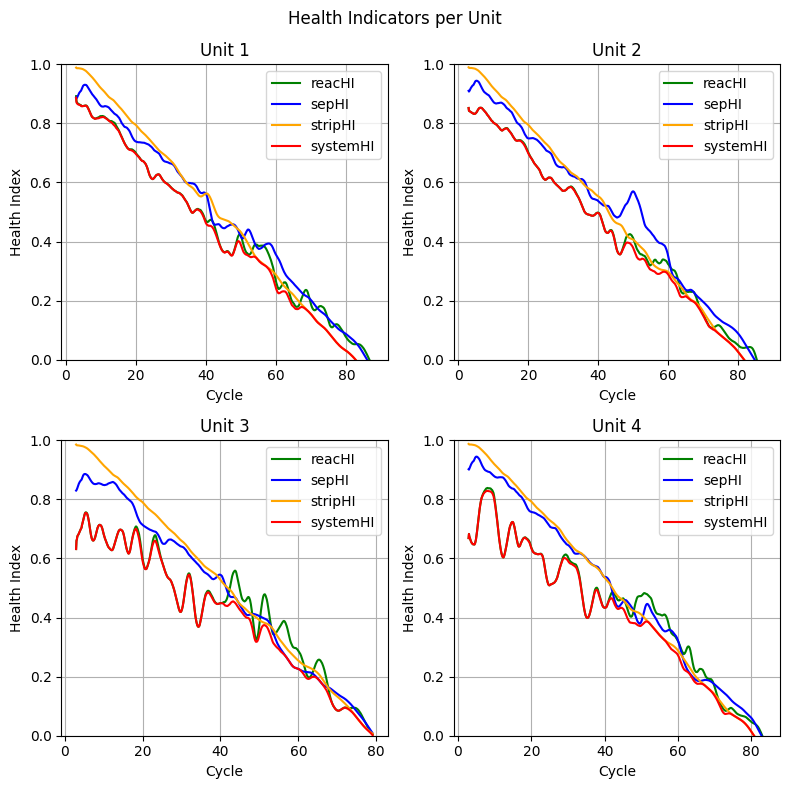

In [13]:

dfHI                = pd.DataFrame({
                                    'id'            : np.array(engineIds1),
                                    'cycle'         : xTimeEnv1.squeeze(),
                                    'systemHI'      : sysHi.flatten(),
                                    'reacHI'        : reacHI.flatten(),
                                    'sepHI'         : sepHI.flatten(),
                                    'stripHI'       : stripHI.flatten(),
                                    })              # Build dataframe for plotting


window_size = 15  # Change this as needed

# List of HI columns to smooth
hi_columns = ['systemHI', 'reacHI', 'sepHI', 'stripHI']

# Apply moving average within each trajectory (by id)
for _ in range(2):
    for col in hi_columns:
        dfHI[col] = (dfHI.groupby('id')[col].transform(lambda x: x.rolling(window=window_size, min_periods=1).mean()))

print(dfHI["cycle"])

# dfHI.to_excel('withTrendability.xlsx', index=False)

# hiThreshold         = max(dfHI.groupby('id')['systemHI'].min())
# upperHI             = max(dfHI.groupby('id')['systemHI'].max())
# dfHI                = dfHI[dfHI['systemHI'] > hiThreshold]                                          # Filter out engines with HI > threshold

# dfHI["systemHI"]         = (dfHI["systemHI"] - hiThreshold) / (upperHI - hiThreshold)           # Normalize HI
dfHI["reacHI"]           = (dfHI["reacHI"] - hiThresholdReac) / (upperHIReac - hiThresholdReac)
dfHI["sepHI"]            = (dfHI["sepHI"] - hiThresholdSep) / (upperHISep - hiThresholdSep)
dfHI["stripHI"]          = (dfHI["stripHI"] - hiThresholdStrip) / (upperHIStrip - hiThresholdStrip)

plot1 = MatPlot()
plot1.plot_HI_by_id(
    dfHI,
    hi_columns=["reacHI", "sepHI", "stripHI", "systemHI"],
    num_rows=2,
    num_cols=2,
    colors=['green', 'blue', 'orange', 'red'],
    title="Health Indicators per Unit",
    y_lim=[0, 1]  # adjust if needed
)


### Evaluate the model

In [14]:
from evaluationFunction import compute_average_hi_metrics

compMetrics = compute_average_hi_metrics(dfHI, hiCol="reacHI")
print("------------------ Reactor -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

compMetrics = compute_average_hi_metrics(dfHI, hiCol="sepHI")
print("------------------ Separator -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

compMetrics = compute_average_hi_metrics(dfHI, hiCol="stripHI")
print("------------------ Stripper -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

compMetrics = compute_average_hi_metrics(dfHI, hiCol="systemHI")
print("------------------ System -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

------------------ Reactor -----------------
Average Robustness: 0.4287028427127546
Average Trendability: 0.9928796841688481
Average Monotonicity: 0.8314760210803688
------------------ Separator -----------------
Average Robustness: 0.4238075704912576
Average Trendability: 0.9969029651651666
Average Monotonicity: 0.9375782608695653
------------------ Stripper -----------------
Average Robustness: 0.4226794722254033
Average Trendability: 0.9997372929187581
Average Monotonicity: 1.0
------------------ System -----------------
Average Robustness: 0.4235753452385721
Average Trendability: 0.9971922813014674
Average Monotonicity: 0.9348325428194993


In [15]:
rulPredictionsOrginal   = rulScaler.inverse_transform(rul)
orginalSysRUL           = rulScaler.inverse_transform(yRul1.reshape(-1, 1))

rmse                    = np.sqrt(np.mean((rulPredictionsOrginal - orginalSysRUL) ** 2))

# Calculate mean RMSE across 100 units
mean_rmse = np.mean(rmse)

print("RMSE of RUL predictions:", mean_rmse)

RMSE of RUL predictions: 1.0656799416232778
